In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df =  pd.read_csv("../Data/SMSSpamCollection",
sep="\t",
names=["label","message"])

print(df.head())


  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...


In [2]:
df.shape    #means 5572 rows and 2 columns
df.columns      #dataset me sirf 2 colums hai
df.info()       #total info
df.isnull().sum()   #means ek bhi missing value nahi hai 
df.duplicated().sum()   #kitni duplicated SMS hai
df["label"].value_counts()  #toal no. of spam and ham messages
df["label"].value_counts(normalize=True)*100    #percentage of spam and ham


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


label
ham     86.593683
spam    13.406317
Name: proportion, dtype: float64

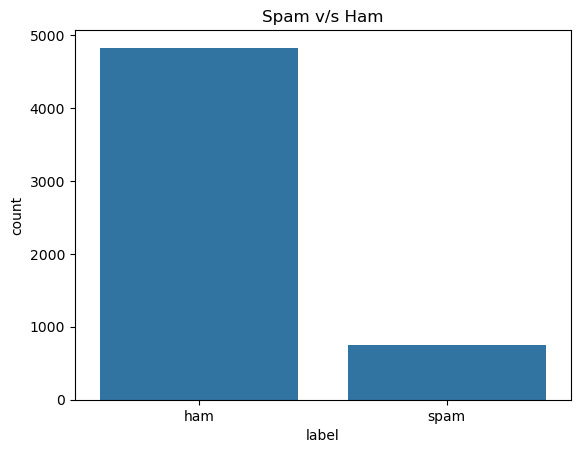

In [3]:
sns.countplot(data=df,x="label")
plt.title("Spam v/s Ham")
plt.show()  


In [4]:
from sklearn.preprocessing import LabelEncoder    #categorical data to numerical data+
encoder = LabelEncoder()
df["label"]= encoder.fit_transform(df["label"])
df.head()

df.duplicated().sum()   #checks duplicate rows
df = df.drop_duplicates()   #removes duplicate
df = df.reset_index(drop=True)  #reset indexes
df.shape            #new shape




(5169, 2)

In [5]:
import nltk   #tokenisation
nltk.download('punkt')
nltk.download('punkt_tab')

from nltk.tokenize import word_tokenize
text = "i love machine learing"
tokens = word_tokenize(text)
print(tokens)

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\rohan\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\rohan\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


['i', 'love', 'machine', 'learing']


In [6]:
import nltk
import string

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer()
ps = PorterStemmer()

stop_words = set(stopwords.words("english"))

def transform_text(text):

    # Lowercase
    text = text.lower()

    # Tokenization
    text = word_tokenize(text)

    # Remove non-alphanumeric
    y = []

    for word in text:
        if word.isalnum():
            y.append(word)

    # Remove stopwords
    text = []

    for word in y:
        if word not in stop_words:
            text.append(word)

    # Stemming
    y = []

    for word in text:
        y.append(ps.stem(word))

    return " ".join(y)


# Apply preprocessing
df["transformed_text"] = df["message"].apply(transform_text)

# Check DataFrame
print(df.head())

# Convert text to TF-IDF vectors
print(df[["message","transformed_text"]].head())

X = tfidf.fit_transform(df["transformed_text"])

print(X.shape,type(X))

   label                                            message  \
0      0  Go until jurong point, crazy.. Available only ...   
1      0                      Ok lar... Joking wif u oni...   
2      1  Free entry in 2 a wkly comp to win FA Cup fina...   
3      0  U dun say so early hor... U c already then say...   
4      0  Nah I don't think he goes to usf, he lives aro...   

                                    transformed_text  
0  go jurong point crazi avail bugi n great world...  
1                              ok lar joke wif u oni  
2  free entri 2 wkli comp win fa cup final tkt 21...  
3                u dun say earli hor u c alreadi say  
4               nah think goe usf live around though  
                                             message  \
0  Go until jurong point, crazy.. Available only ...   
1                      Ok lar... Joking wif u oni...   
2  Free entry in 2 a wkly comp to win FA Cup fina...   
3  U dun say so early hor... U c already then say...   
4  Nah I do

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB

X_train, X_test, y_train, y_test = train_test_split(
    X,
    df["label"],
    test_size=0.2,
    random_state=42
)

clf = MultinomialNB()

clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)

In [8]:
from sklearn.metrics import(
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
def train_classifier(clf, X_train, y_train, X_test, y_test):

    clf.fit(X_train, y_train)

    y_pred = clf.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    return accuracy, precision, recall, f1

In [9]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    ExtraTreesClassifier
)

models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Linear SVM": LinearSVC(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "KNN": KNeighborsClassifier(),
    "Random Forest": RandomForestClassifier(random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "Extra Trees": ExtraTreesClassifier(random_state=42)
}

results = []

for name, model in models.items():

    accuracy, precision, recall, f1 = train_classifier(
        model,
        X_train,
        y_train,
        X_test,
        y_test
    )

    results.append([
        name,
        accuracy,
        precision,
        recall,
        f1
    ])

import pandas as pd

results_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ]
)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
)

print(results_df)

                 Model  Accuracy  Precision    Recall  F1 Score
8          Extra Trees  0.980658   1.000000  0.857143  0.923077
5        Random Forest  0.975822   1.000000  0.821429  0.901961
2           Linear SVM  0.972921   0.959016  0.835714  0.893130
0          Naive Bayes  0.967118   1.000000  0.757143  0.861789
7    Gradient Boosting  0.961315   0.971698  0.735714  0.837398
3        Decision Tree  0.954545   0.844444  0.814286  0.829091
1  Logistic Regression  0.951644   0.959184  0.671429  0.789916
6             AdaBoost  0.928433   0.843750  0.578571  0.686441
4                  KNN  0.900387   1.000000  0.264286  0.418079


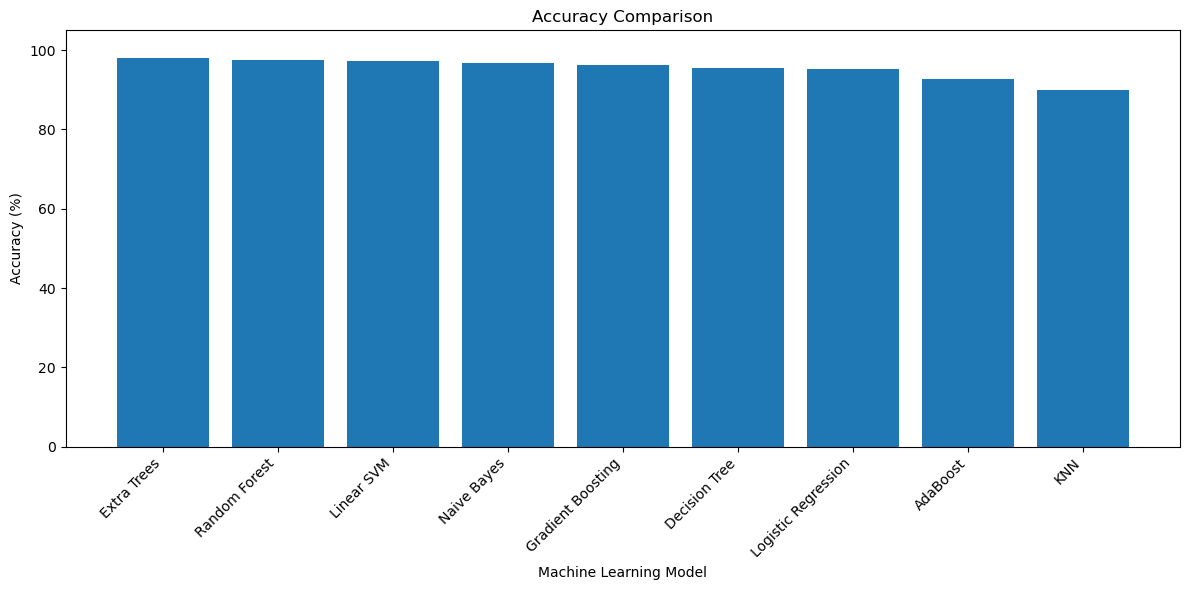

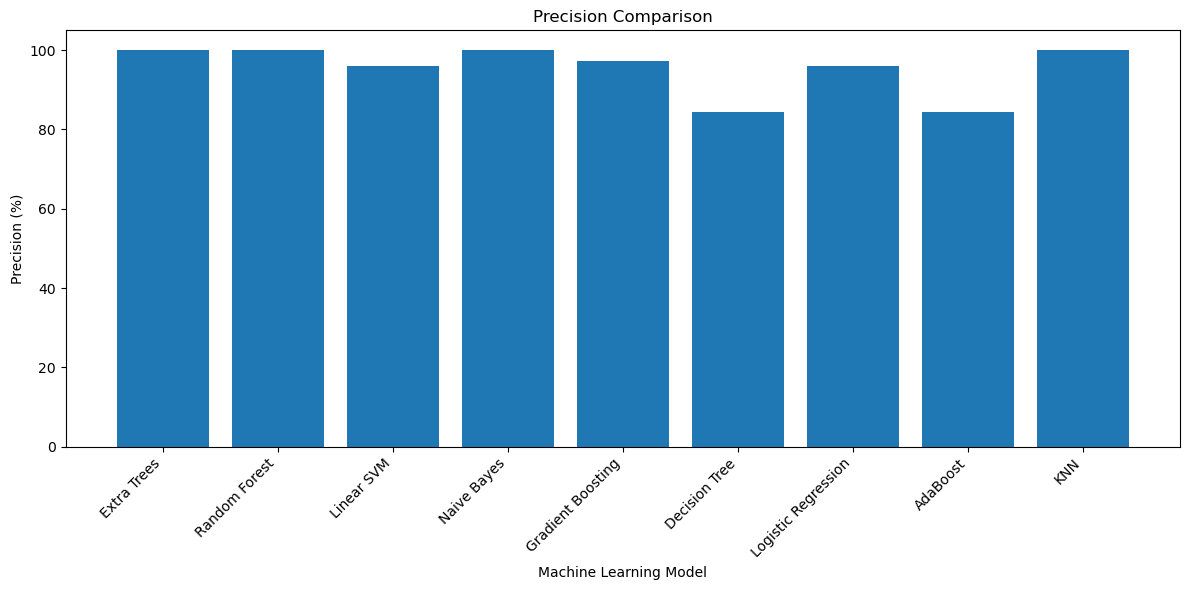

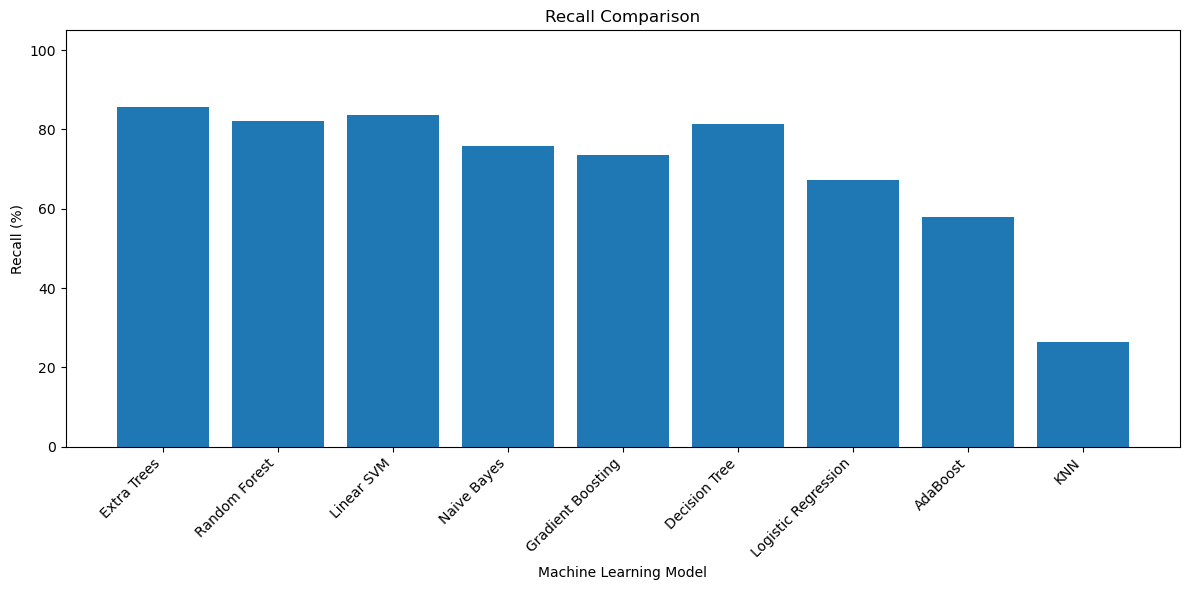

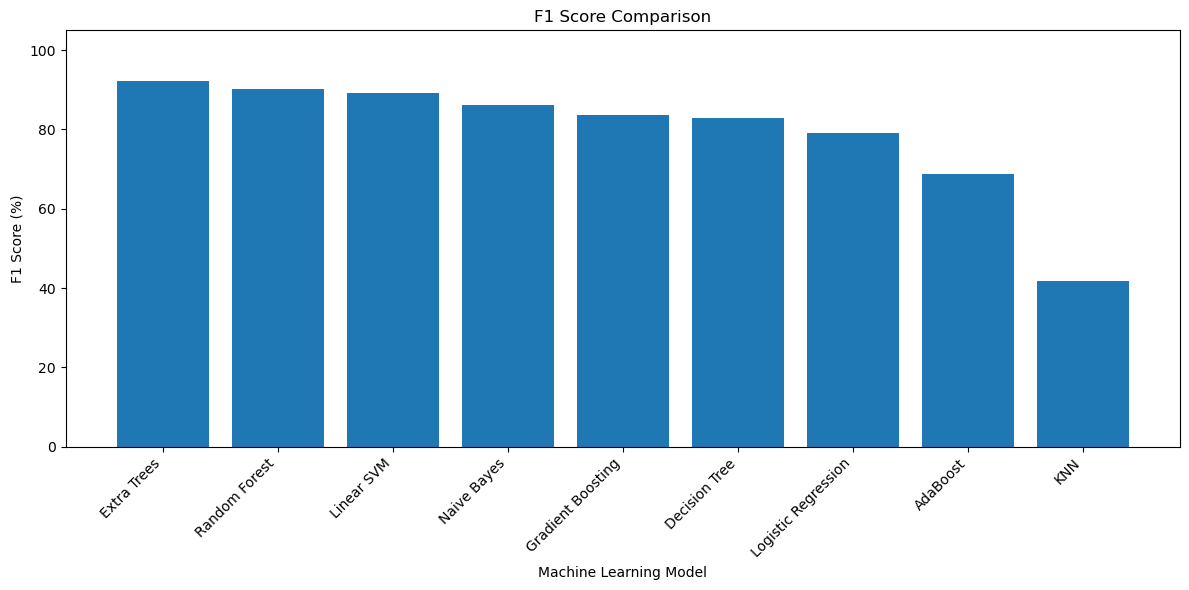

In [14]:
metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

for metric in metrics:
    plt.figure(figsize=(12, 6))

    values = results_df[metric] * 100

    plt.bar(results_df["Model"], values)

    plt.title(f"{metric} Comparison")
    plt.xlabel("Machine Learning Model")
    plt.ylabel(f"{metric} (%)")
    plt.ylim(0, 105)

    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

In [16]:
import pickle
best_model = ExtraTreesClassifier(random_state=42)
best_model.fit(X_train, y_train)
with open("model.pkl","wb") as file:
    pickle.dump(best_model, file)
with open("model.pkl","rb") as file:
    loaded_model = pickle.load(file)

with open("vectorizer.pkl","rb") as file:
    loaded_vectorizer = pickle.load(file)

with open("vectorizer.pkl","wb")as file:
    pickle.dump(tfidf, file)


In [17]:
def predict_spam(message):

    # Step 1: Clean the message
    clean_message = transform_text(message)

    # Step 2: Convert text into TF-IDF features
    vector = loaded_vectorizer.transform([clean_message])

    # Step 3: Predict
    prediction = loaded_model.predict(vector)

    # Step 4: Return result
    if prediction[0] == 1:
        return "Spam"
    else:
        return "Ham"





In [18]:
from sklearn.metrics import accuracy_score

# 1. Training accuracy
train_pred = loaded_model.predict(X_train)
print("Training Accuracy:", accuracy_score(y_train, train_pred))

# 2. Test accuracy
test_pred = loaded_model.predict(X_test)
print("Test Accuracy:", accuracy_score(y_test, test_pred))


spam_msg = df[df["label"] == 1]["message"].iloc[0]

print("Original:")
print(spam_msg)

print("\nProcessed:")
print(transform_text(spam_msg))

print("\nPrediction:")
print(predict_spam(spam_msg))

print("TF-IDF features:", len(loaded_vectorizer.vocabulary_))
print("Model features:", loaded_model.n_features_in_)


Training Accuracy: 1.0
Test Accuracy: 0.9806576402321083
Original:
Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's

Processed:
free entri 2 wkli comp win fa cup final tkt 21st may text fa 87121 receiv entri question std txt rate c appli 08452810075over18

Prediction:
Spam
TF-IDF features: 6782
Model features: 6782
